In [3]:
!pip install -q kagglehub tensorflow nltk scikit-learn pandas


In [4]:


import kagglehub
import os

# Download the dataset again
path = kagglehub.dataset_download(
    "yash9439/eng-hinglish-machine-translation",
    force_download=True
)

print("Downloaded path:", path)
print("Files in folder:", os.listdir(path))

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))


Using Colab cache for faster access to the 'eng-hinglish-machine-translation' dataset.
Downloaded path: /kaggle/input/eng-hinglish-machine-translation
Files in folder: ['Eng - Hinglish']
/kaggle/input/eng-hinglish-machine-translation/Eng - Hinglish/test.txt
/kaggle/input/eng-hinglish-machine-translation/Eng - Hinglish/train.txt
/kaggle/input/eng-hinglish-machine-translation/Eng - Hinglish/dev.txt


In [5]:

import os
import pandas as pd

data_folder = os.path.join(path, "Eng - Hinglish")

train_file = os.path.join(data_folder, "train.txt")
test_file = os.path.join(data_folder, "test.txt")
dev_file = os.path.join(data_folder, "dev.txt")

# Display the first 10 lines of each file
for file_path in [train_file, test_file, dev_file]:
    print("\nFile:", os.path.basename(file_path))

    with open(file_path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            print(repr(line))
            if i == 9:
                break



File: train.txt
'Batman vs Superman\tbatman vs superman \n'
'The director is Zack Snyder , 27 % Rotten Tomatoes , 4.9 / 10 .\tZack Snyder director हैं , 27 % Rotten Tomatoes , 4.9 / 10 . \n'
'Not very popular it seems\tलगता है बहुत popular नहीं है \n'
'But the audiences liked it . It has a B cinema score\tbut audience ने like किया , इसका cinema score भी है \n'
'Yes\tyes \n'
'There is a huge divergence between proffession al critical opinion and regular movie goers\thuge divergence है profession critic की opinion और रुगलर movie देखने वालों के बीच \n'
"I've never seen it\tमैंने तो कभी नहीं देखा है . \n"
'I know the difference .\tमुझे difference पाता है \n'
"I can't believe they used Ben Affleck as Batman\tमुझे तो believe ही नहीं होता कि उन्होंने Ben Affleck को Bataman बनाया . \n"
"So it probably won't get any awards , but should have done well enough at the box office\tSo Probably इसको कोई award नहीं मिला , but box office पर इसको बधिया करना था \n"

File: test.txt
'hello\thello \n'
'hell

In [6]:

import os
import pandas as pd
import re

data_folder = os.path.join(path, "Eng - Hinglish")

def load_translation_file(filename):
    file_path = os.path.join(data_folder, filename)

    df = pd.read_csv(
        file_path,
        sep="\t",
        header=None,
        names=["english", "hinglish"],
        on_bad_lines="skip"
    )

    df = df.dropna()
    df["english"] = df["english"].astype(str).str.strip()
    df["hinglish"] = df["hinglish"].astype(str).str.strip()

    df = df[
        (df["english"] != "") &
        (df["hinglish"] != "")
    ]

    return df.reset_index(drop=True)

train_df = load_translation_file("train.txt")
test_df = load_translation_file("test.txt")
dev_df = load_translation_file("dev.txt")

print("Training pairs:", len(train_df))
print("Testing pairs:", len(test_df))
print("Validation pairs:", len(dev_df))

display(train_df.head())


Training pairs: 7040
Testing pairs: 942
Validation pairs: 1020


,english,hinglish
0,Batman vs Superman,batman vs superman
1,"The director is Zack Snyder , 27 % Rotten Toma...","Zack Snyder director हैं , 27 % Rotten Tomatoe..."
2,Not very popular it seems,लगता है बहुत popular नहीं है
3,But the audiences liked it . It has a B cinema...,"but audience ने like किया , इसका cinema score ..."
4,Yes,yes


In [7]:

def clean_text(text):
    text = str(text).strip()
    text = re.sub(r"\s+", " ", text)
    return text

for frame in [train_df, test_df, dev_df]:
    frame["english"] = frame["english"].apply(clean_text)
    frame["hinglish"] = frame["hinglish"].apply(clean_text)

train_df = train_df.drop_duplicates().reset_index(drop=True)

print("Preprocessing completed!")
display(train_df.head())


Preprocessing completed!


,english,hinglish
0,Batman vs Superman,batman vs superman
1,"The director is Zack Snyder , 27 % Rotten Toma...","Zack Snyder director हैं , 27 % Rotten Tomatoe..."
2,Not very popular it seems,लगता है बहुत popular नहीं है
3,But the audiences liked it . It has a B cinema...,"but audience ने like किया , इसका cinema score ..."
4,Yes,yes


In [8]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

MAX_VOCAB = 15000

# Add start and end tokens to Hinglish sentences
train_hin = [
    "startseq " + s + " endseq" for s in train_df["hinglish"]
]
dev_hin = [
    "startseq " + s + " endseq" for s in dev_df["hinglish"]
]
test_hin = [
    "startseq " + s + " endseq" for s in test_df["hinglish"]
]

# Create tokenizers
eng_tokenizer = Tokenizer(
    num_words=MAX_VOCAB, oov_token="<unk>"
)
hin_tokenizer = Tokenizer(
    num_words=MAX_VOCAB, oov_token="<unk>", filters=""
)

eng_tokenizer.fit_on_texts(train_df["english"])
hin_tokenizer.fit_on_texts(train_hin)

# Convert sentences to sequences
X_train = eng_tokenizer.texts_to_sequences(train_df["english"])
X_dev = eng_tokenizer.texts_to_sequences(dev_df["english"])
X_test = eng_tokenizer.texts_to_sequences(test_df["english"])

Y_train = hin_tokenizer.texts_to_sequences(train_hin)
Y_dev = hin_tokenizer.texts_to_sequences(dev_hin)
Y_test = hin_tokenizer.texts_to_sequences(test_hin)

# Set maximum sequence lengths
MAX_ENG_LEN = min(
    40, max(len(s) for s in X_train)
)
MAX_HIN_LEN = min(
    45, max(len(s) for s in Y_train)
)

# Pad sequences
X_train = pad_sequences(X_train, maxlen=MAX_ENG_LEN, padding="post", truncating="post")
X_dev = pad_sequences(X_dev, maxlen=MAX_ENG_LEN, padding="post", truncating="post")
X_test = pad_sequences(X_test, maxlen=MAX_ENG_LEN, padding="post", truncating="post")

Y_train = pad_sequences(Y_train, maxlen=MAX_HIN_LEN, padding="post", truncating="post")
Y_dev = pad_sequences(Y_dev, maxlen=MAX_HIN_LEN, padding="post", truncating="post")
Y_test = pad_sequences(Y_test, maxlen=MAX_HIN_LEN, padding="post", truncating="post")

# Teacher forcing: previous tokens are inputs, next tokens are targets
decoder_input_train = Y_train[:, :-1]
decoder_target_train = Y_train[:, 1:]

decoder_input_dev = Y_dev[:, :-1]
decoder_target_dev = Y_dev[:, 1:]

decoder_input_test = Y_test[:, :-1]
decoder_target_test = Y_test[:, 1:]

# Ignore padding tokens during loss calculation
train_weights = (decoder_target_train != 0).astype("float32")
dev_weights = (decoder_target_dev != 0).astype("float32")
test_weights = (decoder_target_test != 0).astype("float32")

eng_vocab_size = min(
    MAX_VOCAB, len(eng_tokenizer.word_index) + 1
)
hin_vocab_size = min(
    MAX_VOCAB, len(hin_tokenizer.word_index) + 1
)

print("English vocabulary:", eng_vocab_size)
print("Hinglish vocabulary:", hin_vocab_size)
print("Training shape:", X_train.shape)
print("Decoder target shape:", decoder_target_train.shape)


English vocabulary: 5545
Hinglish vocabulary: 7680
Training shape: (6603, 40)
Decoder target shape: (6603, 44)


In [9]:

import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model

EMBEDDING_DIM = 128
LSTM_UNITS = 256

# Encoder
encoder_inputs = Input(shape=(MAX_ENG_LEN,), name="encoder_inputs")

encoder_embedding_layer = Embedding(
    eng_vocab_size, EMBEDDING_DIM, mask_zero=True
)
encoder_embedding = encoder_embedding_layer(encoder_inputs)

encoder_lstm = LSTM(
    LSTM_UNITS, return_state=True, name="encoder_lstm"
)

_, state_h, state_c = encoder_lstm(encoder_embedding)
encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(
    shape=(MAX_HIN_LEN - 1,), name="decoder_inputs"
)

decoder_embedding_layer = Embedding(
    hin_vocab_size, EMBEDDING_DIM, mask_zero=True
)
decoder_embedding = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(
    LSTM_UNITS, return_sequences=True,
    return_state=True, name="decoder_lstm"
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_embedding, initial_state=encoder_states
)

decoder_dense = Dense(hin_vocab_size, activation="softmax")
decoder_outputs = decoder_dense(decoder_outputs)

model = Model(
    [encoder_inputs, decoder_inputs], decoder_outputs
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy"
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 44)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 40, 128)   │    709,760 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 40)        │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 44, 128)   │    983,040 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    394,240 │ embedding[0][0],  │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 44, 256), │    394,240 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ encoder_lstm[0][… │
│                     │ (None, 256)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 44, 7680)  │  1,973,760 │ decoder_lstm[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,455,040 (16.99 MB)

 Trainable params: 4,455,040 (16.99 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    [X_train, decoder_input_train],
    decoder_target_train,
    sample_weight=train_weights,
    validation_data=(
        [X_dev, decoder_input_dev],
        decoder_target_dev,
        dev_weights
    ),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 339s 3s/step - loss: 6.2136 - val_loss: 5.6602
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 328s 3s/step - loss: 5.5090 - val_loss: 5.5144
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 327s 3s/step - loss: 5.3002 - val_loss: 5.3802
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 317s 3s/step - loss: 5.1075 - val_loss: 5.2633
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 325s 3s/step - loss: 4.9476 - val_loss: 5.1731
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 320s 3s/step - loss: 4.7981 - val_loss: 5.0888
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 312s 3s/step - loss: 4.6608 - val_loss: 5.0264
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 313s 3s/step - loss: 4.5338 - val_loss: 4.9656
Epoch 9/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 304s 3s/step - loss: 4.4170 - val_loss: 4.9242
Epoch 10/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 307s 3s/step - loss: 4.3057 - val_loss: 4.8755


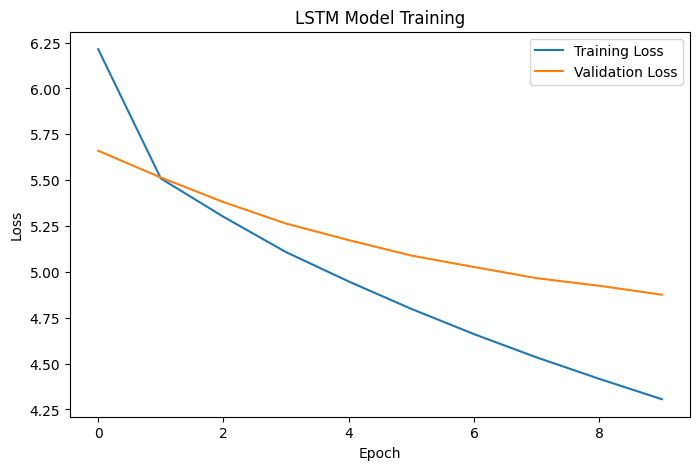

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Model Training")
plt.legend()
plt.show()


In [12]:

# Encoder inference model
encoder_model = Model(encoder_inputs, encoder_states)

# Decoder inference inputs
state_input_h = Input(shape=(LSTM_UNITS,))
state_input_c = Input(shape=(LSTM_UNITS,))
token_input = Input(shape=(1,))

token_embedding = decoder_embedding_layer(token_input)

step_output, next_h, next_c = decoder_lstm(
    token_embedding,
    initial_state=[state_input_h, state_input_c]
)

step_output = decoder_dense(step_output)

decoder_model = Model(
    [token_input, state_input_h, state_input_c],
    [step_output, next_h, next_c]
)

word_index = hin_tokenizer.word_index
index_word = hin_tokenizer.index_word

start_id = word_index["startseq"]
end_id = word_index["endseq"]

def translate(sentence):
    sequence = eng_tokenizer.texts_to_sequences([clean_text(sentence)])
    sequence = pad_sequences(
        sequence,
        maxlen=MAX_ENG_LEN,
        padding="post",
        truncating="post"
    )

    states = encoder_model.predict(sequence, verbose=0)
    token = np.array([[start_id]])
    words = []

    for _ in range(MAX_HIN_LEN - 1):
        output, h, c = decoder_model.predict(
            [token] + states, verbose=0
        )

        predicted_id = int(np.argmax(output[0, -1, :]))

        if predicted_id == end_id or predicted_id == 0:
            break

        word = index_word.get(predicted_id, "<unk>")

        if word != "startseq":
            words.append(word)

        token = np.array([[predicted_id]])
        states = [h, c]

    return " ".join(words)

print(translate("How are you?"))


क्या तुम ?


In [13]:

unseen_sentences = [
    "How are you?",
    "What is your name?",
    "I am going to school.",
    "Please help me.",
    "I will call you tomorrow."
]

for sentence in unseen_sentences:
    print("English:", sentence)
    print("Hinglish:", translate(sentence))
    print("-" * 40)


English: How are you?
Hinglish: क्या तुम ?
----------------------------------------
English: What is your name?
Hinglish: क्या तुम क्या है ?
----------------------------------------
English: I am going to school.
Hinglish: मुझे लगता है
----------------------------------------
English: Please help me.
Hinglish: hello
----------------------------------------
English: I will call you tomorrow.
Hinglish: मुझे लगता है
----------------------------------------


In [ ]:

from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

references = []
hypotheses = []

n = min(200, len(test_df))
smooth = SmoothingFunction().method1

for i in range(n):
    actual = test_df.iloc[i]["hinglish"]
    predicted = translate(test_df.iloc[i]["english"])

    references.append([actual.split()])
    hypotheses.append(predicted.split())

bleu = corpus_bleu(
    references,
    hypotheses,
    smoothing_function=smooth
)

print("BLEU Score:", round(bleu, 4))
print("BLEU Score (%):", round(bleu * 100, 2))
